In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Diseñe un proyecto de **6 actividades** (A, B, …) con duraciones enteras que cumpla *todas* estas condiciones:

- exactamente 2 actividades iniciales;
- su grafo PERT con el mínimo número de ficticias tiene exactamente 1 ficticia(s);
- tiene exactamente 2 rutas críticas;
- al menos una actividad con holgura total positiva;
- ninguna prelación redundante.

In [4]:
pregunta_1 = "1. Escriba el cuadro de prelaciones y duraciones de su proyecto.  "
pregunta_2 = "2. Compruebe con la librería cada una de las condiciones.  "
pregunta_3 = "3. ¿Qué condición le ha resultado más difícil de conseguir y por qué? ¿Qué cambio mínimo en las duraciones haría que sólo hubiera una ruta crítica?  "
pregunta_4 = "4. ¿Es único el proyecto que cumple las condiciones? Dé otro distinto (basta cambiar una prelación o una duración sin violar ninguna condición) o argumente que no existe.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Escriba el cuadro de prelaciones y duraciones de su proyecto.  

2. Compruebe con la librería cada una de las condiciones.  

3. ¿Qué condición le ha resultado más difícil de conseguir y por qué? ¿Qué cambio mínimo en las duraciones haría que sólo hubiera una ruta crítica?  

4. ¿Es único el proyecto que cumple las condiciones? Dé otro distinto (basta cambiar una prelación o una duración sin violar ninguna condición) o argumente que no existe.  

# Resolución

Hay muchas soluciones; la que sigue la encontró un programa que genera proyectos al azar y comprueba las condiciones (el mismo método que puede usar el lector: proponer, comprobar, corregir). Para tener varias rutas críticas conviene construir rutas en paralelo y ajustar después las duraciones para que sumen lo mismo; las ficticias aparecen cuando dos actividades comparten algunas predecesoras pero no todas.

## Apartado 1

In [5]:
display(Markdown(pregunta_1))

1. Escriba el cuadro de prelaciones y duraciones de su proyecto.  

In [6]:
#| tbl-cap: "Una solución"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration
    ('A'     , '---'      , 7       ),
    ('B'     , '---'      , 7       ),
    ('C'     , 'A,B'      , 3       ),
    ('D'     , 'B'        , 2       ),
    ('E'     , 'C,D'      , 3       ),
    ('F'     , 'E'        , 2       ),
], columns=['activity', 'predecessor', 'duration']).set_index('activity')
datos_enunciado

,predecessor,duration
activity,,
A,---,7
B,---,7
C,"A,B",3
D,B,2
E,"C,D",3
F,E,2


## Apartado 2

In [7]:
display(Markdown(pregunta_2))

2. Compruebe con la librería cada una de las condiciones.  

In [8]:
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
rutas_criticas = proyecto.critical_path(datos_proyecto['duration'])
G = nx.DiGraph([(p, a) for a, ps in prelaciones.immediate_predecessor.items() for p in ps]); G.add_nodes_from(datos_proyecto.index)
redundantes = sorted(set(G.edges) - set(nx.transitive_reduction(G).edges))
comprobacion = pd.DataFrame({
    'exigido': [6, 2, 1, 2, '≥ 1', 0],
    'obtenido': [len(datos_proyecto), len(prelaciones.start_activities), len(proyecto.dummies), len(rutas_criticas),
                 int((calendario['H_total'] > 0).sum()), len(redundantes)]},
    index=['actividades', 'iniciales', 'ficticias', 'rutas críticas', 'con holgura positiva', 'prelaciones redundantes'])
comprobacion['cumple'] = [str(e) == str(o) if e != '≥ 1' else o >= 1 for e, o in zip(comprobacion['exigido'], comprobacion['obtenido'])]
comprobacion

,exigido,obtenido,cumple
actividades,6,6,True
iniciales,2,2,True
ficticias,1,1,True
rutas críticas,2,2,True
con holgura positiva,≥ 1,1,True
prelaciones redundantes,0,0,True


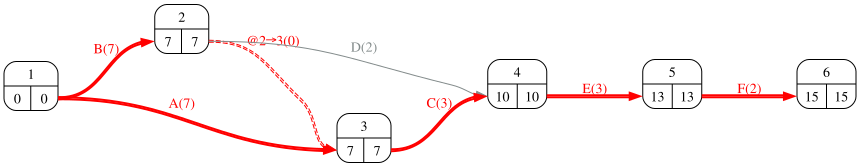

In [9]:
#| fig-cap: "Grafo PERT con las rutas críticas"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

In [10]:
for nombre, acts in rutas_criticas.items():
    print(f'{nombre}: {" - ".join(acts)}')
calendario[['inicio_mas_temprano', 'fin_mas_temprano', 'H_total']]

Route_1: A - C - E - F
Route_2: B - C - E - F


,inicio_mas_temprano,fin_mas_temprano,H_total
activity,,,
A,0,7,0
B,0,7,0
C,7,10,0
D,7,9,1
E,10,13,0
F,13,15,0


## Apartado 3

In [11]:
display(Markdown(pregunta_3))

3. ¿Qué condición le ha resultado más difícil de conseguir y por qué? ¿Qué cambio mínimo en las duraciones haría que sólo hubiera una ruta crítica?  

In [12]:
R = proyecto.path_matrix(dummies=False)
Rt = R @ datos_proyecto['duration'][R.columns]
criticas = Rt.index[Rt == Rt.max()].tolist()
# actividad que está en una ruta crítica pero no en todas: alargarla 1 deja una sola crítica
solo_en_una = [a for a in R.columns if 0 < R.loc[criticas, a].sum() < len(criticas)]
a_cambiar = solo_en_una[0] if solo_en_una else None
if a_cambiar:
    d2 = datos_proyecto['duration'].copy(); d2[a_cambiar] += 1
    n_crit2 = len(proyecto.critical_path(d2))
    display(Markdown(f'La condición más exigente suele ser el número exacto de rutas críticas (hay que igualar sumas). Alargando {a_cambiar} un día quedan {n_crit2} ruta(s) crítica(s).'))
else:
    display(Markdown('Todas las actividades críticas están en todas las rutas críticas; habría que acortar una actividad común y alargar otra.'))

La condición más exigente suele ser el número exacto de rutas críticas (hay que igualar sumas). Alargando A un día quedan 1 ruta(s) crítica(s).

## Apartado 4

In [13]:
display(Markdown(pregunta_4))

4. ¿Es único el proyecto que cumple las condiciones? Dé otro distinto (basta cambiar una prelación o una duración sin violar ninguna condición) o argumente que no existe.  

No es único: en general hay muchísimos proyectos que cumplen las condiciones. Por ejemplo, multiplicar todas las duraciones por 2 conserva las rutas críticas, las holguras positivas, las ficticias y las iniciales; o permutar los nombres de las actividades. Una solución *estructuralmente* distinta se obtiene cambiando una prelación y recomprobando.

In [14]:
datos_otro = datos_proyecto.copy()
datos_otro['duration'] = datos_otro['duration'] * 2
p2 = PredecessorTable.from_dataframe_of_strings(datos_otro, activity='activity', predecessor='predecessor').create_project()
Markdown(f'Con las duraciones dobladas: {len(p2.critical_path(datos_otro["duration"]))} rutas críticas, {len(p2.dummies)} ficticias, '
         f'{int((p2.calendar(datos_otro["duration"])["H_total"] > 0).sum())} actividades con holgura: las mismas condiciones.')

Con las duraciones dobladas: 2 rutas críticas, 1 ficticias, 1 actividades con holgura: las mismas condiciones.